# MI3031 – Chương 4: Hồi quy tuyến tính đơn
## Phân tích mối quan hệ giữa **điểm số trước đó** và **chỉ số kết quả học tập** của sinh viên

**Học phần:** MI3031 – Thống kê ứng dụng  |  **Nhóm:** 4  |  **Phạm vi:** Mục 4.1 – Hồi quy tuyến tính đơn (1 biến phụ thuộc, 1 biến độc lập)

**Thành viên:** *(điền họ tên – MSSV các thành viên)*

---
### Cấu trúc bài làm (bám sát slide Chương 4, mục 4.1)

| Phần | Nội dung | Mục trong slide |
|---|---|---|
| 1 | Chuẩn bị môi trường, đọc dữ liệu | – |
| 2 | Khám phá dữ liệu (EDA) và chọn biến | – |
| 3 | Mô hình hồi quy tuyến tính đơn biến, giả thiết | 4.1.1 |
| 4 | Ước lượng bằng phương pháp bình phương nhỏ nhất | 4.1.2 |
| 5 | Tính chất của ước lượng, ước lượng $\sigma^2$, sai số chuẩn | 4.1.3 |
| 6 | Kiểm định giả thuyết (t, F, ANOVA) | 4.1.4 |
| 7 | Khoảng tin cậy và khoảng dự đoán | 4.1.5 |
| 8 | Tính đủ của mô hình: phần dư, $R^2$, ý nghĩa hệ số chặn | 4.1.6 |
| 9 | Hồi quy trên các phép biến đổi | 4.1.7 |
| 10 | Dự đoán và đánh giá trên tập kiểm tra | ứng dụng |
| 11 | Kết luận | – |

## 1. Chuẩn bị môi trường và đọc dữ liệu

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "figure.autolayout": True})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
ALPHA = 0.05          # mức ý nghĩa; độ tin cậy 1 - ALPHA = 95%

In [2]:
# Tìm file dữ liệu (đặt cùng thư mục với notebook hoặc trong thư mục data/)
CANDIDATES = ["Student_Performance.csv", "StudentsPerformance.csv",
              "data/Student_Performance.csv", "data/StudentsPerformance.csv"]
DATA_PATH = next((Path(p) for p in CANDIDATES if Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Không tìm thấy file CSV. Hãy đặt Student_Performance.csv cạnh notebook.")

df = pd.read_csv(DATA_PATH)
print("Đã đọc:", DATA_PATH, "| kích thước:", df.shape)
df.head()

Đã đọc: Student_Performance.csv | kích thước: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0000
1,4,82,No,4,2,65.0000
2,8,51,Yes,7,2,45.0000
3,5,52,Yes,5,2,36.0000
4,7,75,No,8,5,66.0000


## 2. Khám phá dữ liệu (EDA) và chọn biến

**Bộ dữ liệu** *Student Performance* gồm 10 000 sinh viên, với các biến:

| Biến | Ý nghĩa | Kiểu |
|---|---|---|
| `Hours Studied` | Số giờ học | số nguyên |
| `Previous Scores` | Điểm các bài kiểm tra trước đó | số nguyên |
| `Extracurricular Activities` | Có tham gia ngoại khóa (Yes/No) | phân loại |
| `Sleep Hours` | Số giờ ngủ trung bình mỗi ngày | số nguyên |
| `Sample Question Papers Practiced` | Số đề mẫu đã luyện | số nguyên |
| **`Performance Index`** | **Chỉ số kết quả học tập** | số thực – **biến phụ thuộc $Y$** |

In [3]:
print(df.info())
print("\nSố giá trị thiếu:", int(df.isna().sum().sum()))
print("Số dòng trùng lặp:", int(df.duplicated().sum()))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB
None

Số giá trị thiếu: 0
Số dòng trùng lặp: 127


,count,mean,std,min,25%,50%,75%,max
Hours Studied,"10,000.0000",4.9929,2.5893,1.0000,3.0000,5.0000,7.0000,9.0000
Previous Scores,"10,000.0000",69.4457,17.3432,40.0000,54.0000,69.0000,85.0000,99.0000
Sleep Hours,"10,000.0000",6.5306,1.6959,4.0000,5.0000,7.0000,8.0000,9.0000
Sample Question Papers Practiced,"10,000.0000",4.5833,2.8673,0.0000,2.0000,5.0000,7.0000,9.0000
Performance Index,"10,000.0000",55.2248,19.2126,10.0000,40.0000,55.0000,71.0000,100.0000


> **Nhận xét.** Dữ liệu không có giá trị thiếu. Có một số dòng trùng lặp; vì các biến đều là số nguyên nhận giá trị trong miền nhỏ nên trùng lặp là điều tự nhiên (hai sinh viên khác nhau có thể cho cùng bộ giá trị), do đó **ta giữ nguyên** các dòng này.

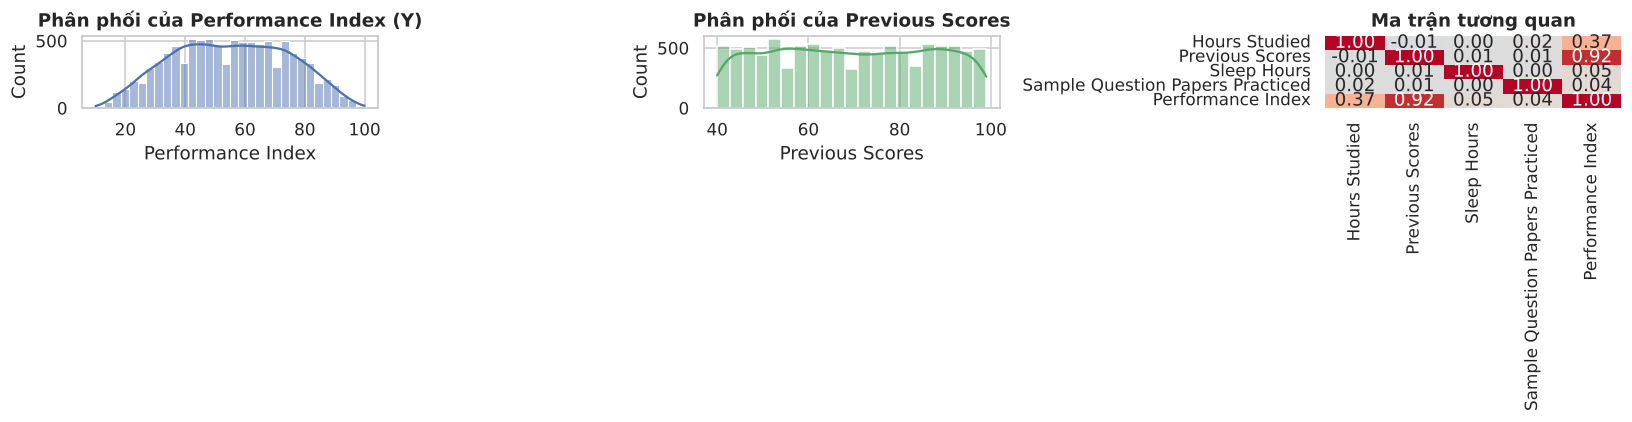

In [4]:
Y_COL = "Performance Index"
num_cols = [c for c in df.select_dtypes("number").columns if c != Y_COL]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df[Y_COL], kde=True, ax=axes[0], color="#4C72B0"); axes[0].set_title("Phân phối của Performance Index (Y)")
sns.histplot(df["Previous Scores"], kde=True, ax=axes[1], color="#55A868"); axes[1].set_title("Phân phối của Previous Scores")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2], cbar=False)
axes[2].set_title("Ma trận tương quan")
plt.show()

### 2.1. Chọn biến độc lập
Bài toán chỉ yêu cầu **một** biến độc lập. Ta hồi quy đơn $Y$ theo từng biến định lượng, rồi chọn biến giải thích $Y$ tốt nhất (hệ số xác định $R^2$ lớn nhất).

In [5]:
rows = []
for c in num_cols:
    r = stats.linregress(df[c], df[Y_COL])
    rows.append({"Biến độc lập": c, "Hệ số góc": r.slope, "Hệ số tương quan r": r.rvalue,
                 "R²": r.rvalue**2, "p-value (β1=0)": r.pvalue})
pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True)

,Biến độc lập,Hệ số góc,Hệ số tương quan r,R²,p-value (β1=0)
0,Previous Scores,1.0138,0.9152,0.8376,0.0000
1,Hours Studied,2.7731,0.3737,0.1397,0.0000
2,Sleep Hours,0.5450,0.0481,0.0023,0.0000
3,Sample Question Papers Practiced,0.2899,0.0433,0.0019,0.0000


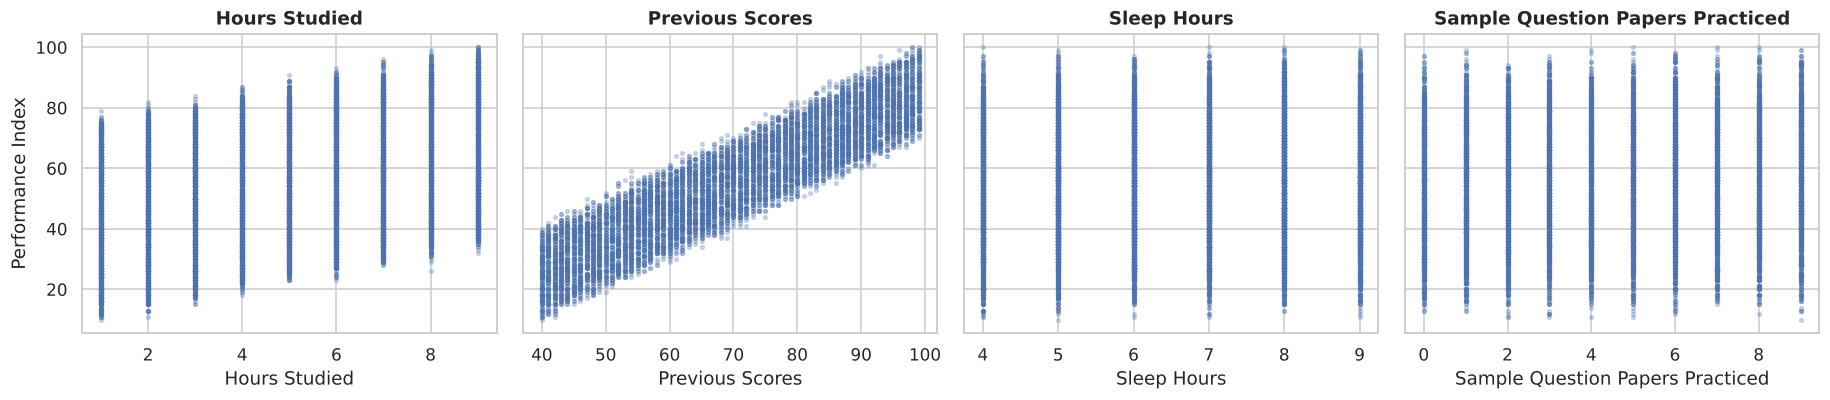

In [6]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(4.2 * len(num_cols), 3.8), sharey=True)
for ax, c in zip(axes, num_cols):
    ax.scatter(df[c], df[Y_COL], s=6, alpha=0.25)
    ax.set_title(c); ax.set_xlabel(c)
axes[0].set_ylabel(Y_COL)
plt.show()

> **Kết luận chọn biến.** `Previous Scores` có tương quan rất mạnh với `Performance Index` ($r\approx 0{,}92$), vượt xa ba biến còn lại. Vì vậy:
>
> - **Biến phụ thuộc:** $Y$ = `Performance Index`
> - **Biến độc lập:** $x$ = `Previous Scores`

In [7]:
X_COL = "Previous Scores"
x = df[X_COL].to_numpy(dtype=float)
y = df[Y_COL].to_numpy(dtype=float)
n = len(x)
print(f"n = {n} | x ∈ [{x.min():.0f}, {x.max():.0f}] | y ∈ [{y.min():.0f}, {y.max():.0f}]")

n = 10000 | x ∈ [40, 99] | y ∈ [10, 100]


## 3. Mô hình hồi quy tuyến tính đơn biến *(mục 4.1.1)*

### 3.1. Lý thuyết
Mô hình hồi quy tuyến tính đơn biến:
$$Y_i=\beta_0+\beta_1 x_i+\varepsilon_i,\qquad i=1,\dots,n,$$
trong đó $\beta_0$ là **hệ số chặn**, $\beta_1$ là **hệ số góc**, $\varepsilon_i$ là sai số ngẫu nhiên.

**Giả thiết của mô hình:**
1. $\mathbb E(\varepsilon_i)=0$ ;
2. $\operatorname{Var}(\varepsilon_i)=\sigma^2$ không đổi (phương sai đồng nhất);
3. $\varepsilon_1,\dots,\varepsilon_n$ độc lập;
4. $\varepsilon_i\sim N(0,\sigma^2)$ (để kiểm định và xây dựng khoảng tin cậy chính xác).

Tức là $\varepsilon_i\sim N_{iid}(0,\sigma^2)$ và $Y_i\sim N(\beta_0+\beta_1x_i,\ \sigma^2)$.

- **Hàm hồi quy lý thuyết:** $\mu_{Y|x}=\mathbb E(Y|x)=\beta_0+\beta_1x$.
- **Đường hồi quy được hiệu chỉnh (mẫu):** $\hat y=\hat\beta_0+\hat\beta_1x$.

### 3.2. Áp dụng vào dữ liệu
$$\text{Performance Index}_i=\beta_0+\beta_1\cdot\text{Previous Scores}_i+\varepsilon_i$$
Biểu đồ phân tán dưới đây cho thấy quan hệ gần tuyến tính, điều kiện cần để dùng mô hình này.

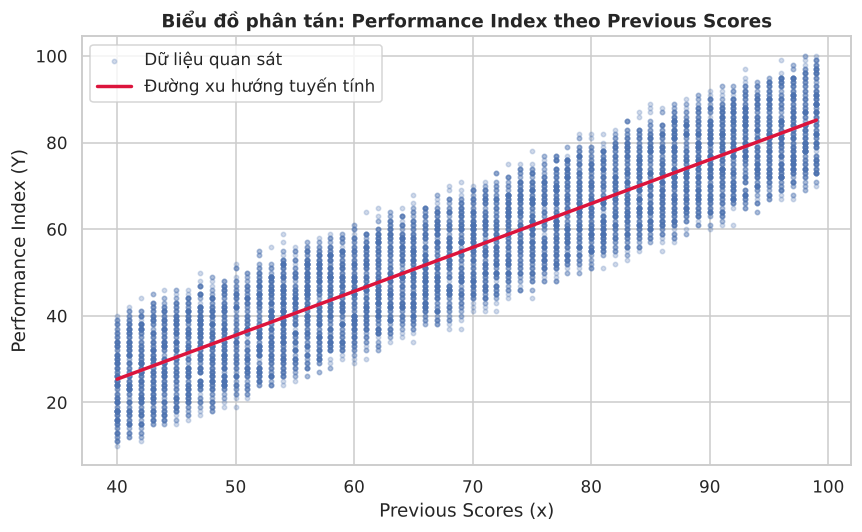

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=8, alpha=0.25, label="Dữ liệu quan sát")
sns.regplot(x=x, y=y, scatter=False, color="crimson", ci=95, ax=ax, label="Đường xu hướng tuyến tính")
ax.set_xlabel("Previous Scores (x)"); ax.set_ylabel("Performance Index (Y)")
ax.set_title("Biểu đồ phân tán: Performance Index theo Previous Scores"); ax.legend()
plt.show()

## 4. Phương pháp bình phương nhỏ nhất *(mục 4.1.2)*

### 4.1. Lý thuyết
Chọn $\hat\beta_0,\hat\beta_1$ để cực tiểu tổng bình phương sai số
$$L(\beta_0,\beta_1)=\sum_{i=1}^n\big(y_i-\beta_0-\beta_1x_i\big)^2 .$$
Giải hệ phương trình chuẩn $\partial L/\partial\beta_0=\partial L/\partial\beta_1=0$ ta được
$$\hat\beta_1=\frac{S_{xy}}{S_{xx}},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x,$$
với
$$S_{xx}=\sum_{i}(x_i-\bar x)^2,\quad S_{xy}=\sum_i(x_i-\bar x)(y_i-\bar y),\quad S_{yy}=\sum_i(y_i-\bar y)^2 .$$

### 4.2. Tính trực tiếp theo công thức

In [9]:
x_bar, y_bar = x.mean(), y.mean()
Sxx = np.sum((x - x_bar) ** 2)
Sxy = np.sum((x - x_bar) * (y - y_bar))
Syy = np.sum((y - y_bar) ** 2)

b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar

print(f"x̄ = {x_bar:.4f}   ȳ = {y_bar:.4f}")
print(f"Sxx = {Sxx:,.2f}   Sxy = {Sxy:,.2f}   Syy = {Syy:,.2f}")
print(f"\nβ̂1 = Sxy/Sxx = {b1:.6f}")
print(f"β̂0 = ȳ - β̂1·x̄ = {b0:.6f}")
print(f"\nĐường hồi quy: ŷ = {b0:.4f} + {b1:.4f}·x")

x̄ = 69.4457   ȳ = 55.2248
Sxx = 3,007,548.52   Sxy = 3,049,163.07   Syy = 3,690,854.65

β̂1 = Sxy/Sxx = 1.013837
β̂0 = ȳ - β̂1·x̄ = -15.181799

Đường hồi quy: ŷ = -15.1818 + 1.0138·x


### 4.3. Kiểm chứng bằng thư viện (`numpy`, `statsmodels`, `scikit-learn`)

In [10]:
X_sm = sm.add_constant(x)                       # thêm cột 1 cho hệ số chặn
ols = sm.OLS(y, X_sm).fit()
sk = LinearRegression().fit(x.reshape(-1, 1), y)
npfit = np.polyfit(x, y, 1)

pd.DataFrame({
    "β̂0 (hệ số chặn)": [b0, npfit[1], ols.params[0], sk.intercept_],
    "β̂1 (hệ số góc)":  [b1, npfit[0], ols.params[1], sk.coef_[0]],
}, index=["Công thức tay", "numpy.polyfit", "statsmodels OLS", "scikit-learn"])

,β̂0 (hệ số chặn),β̂1 (hệ số góc)
Công thức tay,-15.1818,1.0138
numpy.polyfit,-15.1818,1.0138
statsmodels OLS,-15.1818,1.0138
scikit-learn,-15.1818,1.0138


Bốn cách tính cho kết quả trùng nhau, xác nhận công thức bình phương nhỏ nhất đã cài đặt đúng.

### 4.4. Các tính chất đại số của đường hồi quy
Từ hệ phương trình chuẩn, phần dư $e_i=y_i-\hat y_i$ thỏa mãn $\sum e_i=0$, $\sum x_ie_i=0$, và đường hồi quy đi qua điểm $(\bar x,\bar y)$.

In [11]:
y_hat = b0 + b1 * x
e = y - y_hat

print(f"Σ eᵢ        = {e.sum():.3e}   (≈ 0)")
print(f"Σ xᵢ·eᵢ     = {np.sum(x * e):.3e}   (≈ 0)")
print(f"ŷ(x̄) - ȳ    = {(b0 + b1 * x_bar) - y_bar:.3e}   (≈ 0, đường thẳng đi qua (x̄, ȳ))")

Σ eᵢ        = 4.465e-11   (≈ 0)
Σ xᵢ·eᵢ     = 3.718e-09   (≈ 0)
ŷ(x̄) - ȳ    = 0.000e+00   (≈ 0, đường thẳng đi qua (x̄, ȳ))


### 4.5. Diễn giải hệ số
- $\hat\beta_1$: khi điểm trước đó tăng thêm **1 điểm**, chỉ số kết quả học tập **trung bình** tăng khoảng $\hat\beta_1$ đơn vị.
- $\hat\beta_0$: giá trị trung bình ước lượng của $Y$ khi $x=0$ — xem thảo luận ở mục 8.4.

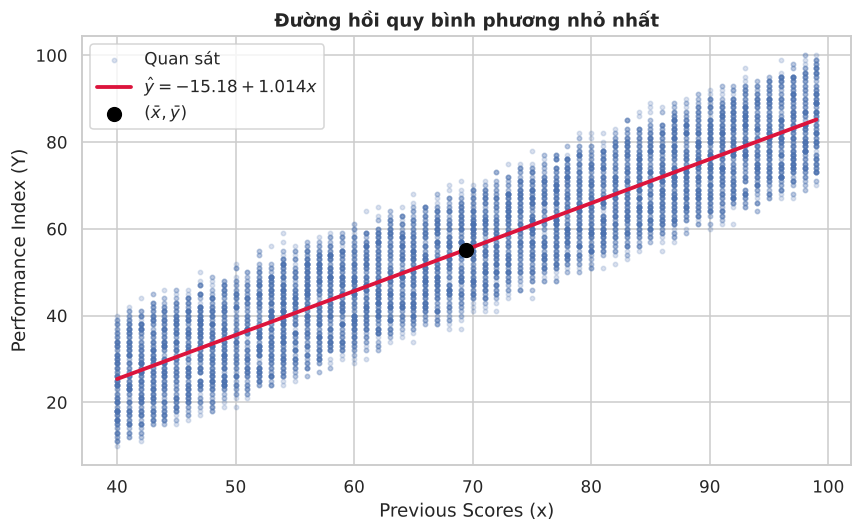

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=8, alpha=0.2, label="Quan sát")
xs = np.linspace(x.min(), x.max(), 200)
ax.plot(xs, b0 + b1 * xs, color="crimson", lw=2.5, label=fr"$\hat y={b0:.2f}+{b1:.3f}x$")
ax.scatter([x_bar], [y_bar], color="black", s=80, zorder=5, label=r"$(\bar x,\bar y)$")
ax.set_xlabel("Previous Scores (x)"); ax.set_ylabel("Performance Index (Y)")
ax.set_title("Đường hồi quy bình phương nhỏ nhất"); ax.legend()
plt.show()

## 5. Tính chất của ước lượng bình phương nhỏ nhất *(mục 4.1.3)*

### 5.1. Lý thuyết
Với giả thiết của mô hình, $\hat\beta_0,\hat\beta_1$ là **ước lượng không chệch** và
$$\mathbb E(\hat\beta_1)=\beta_1,\quad \operatorname{Var}(\hat\beta_1)=\frac{\sigma^2}{S_{xx}},\qquad
\mathbb E(\hat\beta_0)=\beta_0,\quad \operatorname{Var}(\hat\beta_0)=\sigma^2\Big[\frac1n+\frac{\bar x^2}{S_{xx}}\Big].$$

Phương sai $\sigma^2$ chưa biết được ước lượng không chệch bởi
$$\hat\sigma^2=\frac{SS_E}{n-2}=\frac{\sum_i (y_i-\hat y_i)^2}{n-2}\quad\Rightarrow\quad
se(\hat\beta_1)=\sqrt{\frac{\hat\sigma^2}{S_{xx}}},\quad se(\hat\beta_0)=\sqrt{\hat\sigma^2\Big[\frac1n+\frac{\bar x^2}{S_{xx}}\Big]}.$$

### 5.2. Tính toán trên dữ liệu

In [13]:
SSE = np.sum(e ** 2)
sigma2_hat = SSE / (n - 2)
sigma_hat = np.sqrt(sigma2_hat)

se_b1 = np.sqrt(sigma2_hat / Sxx)
se_b0 = np.sqrt(sigma2_hat * (1 / n + x_bar ** 2 / Sxx))

print(f"SSE        = {SSE:,.2f}")
print(f"σ̂²  = SSE/(n-2) = {sigma2_hat:.4f}   →   σ̂ = {sigma_hat:.4f}")
print(f"se(β̂1) = {se_b1:.6f}   (statsmodels: {ols.bse[1]:.6f})")
print(f"se(β̂0) = {se_b0:.6f}   (statsmodels: {ols.bse[0]:.6f})")

SSE        = 599,501.22
σ̂²  = SSE/(n-2) = 59.9621   →   σ̂ = 7.7435
se(β̂1) = 0.004465   (statsmodels: 0.004465)
se(β̂0) = 0.319605   (statsmodels: 0.319605)


### 5.3. Minh họa tính không chệch bằng mô phỏng
Giữ cố định 100 giá trị $x$, coi đường hồi quy ước lượng là "sự thật" $(\beta_0,\beta_1,\sigma)$, sinh lặp lại 5 000 mẫu $Y_i=\beta_0+\beta_1x_i+\varepsilon_i$ rồi ước lượng lại. Nếu lý thuyết đúng thì trung bình các $\hat\beta$ tiến tới giá trị thật và phương sai tiến tới $\sigma^2/S_{xx}$.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
x_fix = rng.choice(x, size=100, replace=False)
Sxx_fix = np.sum((x_fix - x_fix.mean()) ** 2)

B = 5000
b1_sim, b0_sim = np.empty(B), np.empty(B)
for k in range(B):
    y_sim = b0 + b1 * x_fix + rng.normal(0, sigma_hat, size=x_fix.size)
    s1 = np.sum((x_fix - x_fix.mean()) * (y_sim - y_sim.mean())) / Sxx_fix
    b1_sim[k] = s1
    b0_sim[k] = y_sim.mean() - s1 * x_fix.mean()

var_b1_th = sigma_hat ** 2 / Sxx_fix
var_b0_th = sigma_hat ** 2 * (1 / x_fix.size + x_fix.mean() ** 2 / Sxx_fix)
pd.DataFrame({
    "Giá trị thật": [b0, b1],
    "Trung bình mô phỏng": [b0_sim.mean(), b1_sim.mean()],
    "Var lý thuyết": [var_b0_th, var_b1_th],
    "Var mô phỏng": [b0_sim.var(ddof=1), b1_sim.var(ddof=1)],
}, index=["β0", "β1"])

,Giá trị thật,Trung bình mô phỏng,Var lý thuyết,Var mô phỏng
β0,-15.1818,-15.1882,11.2433,11.3885
β1,1.0138,1.0139,0.0022,0.0022


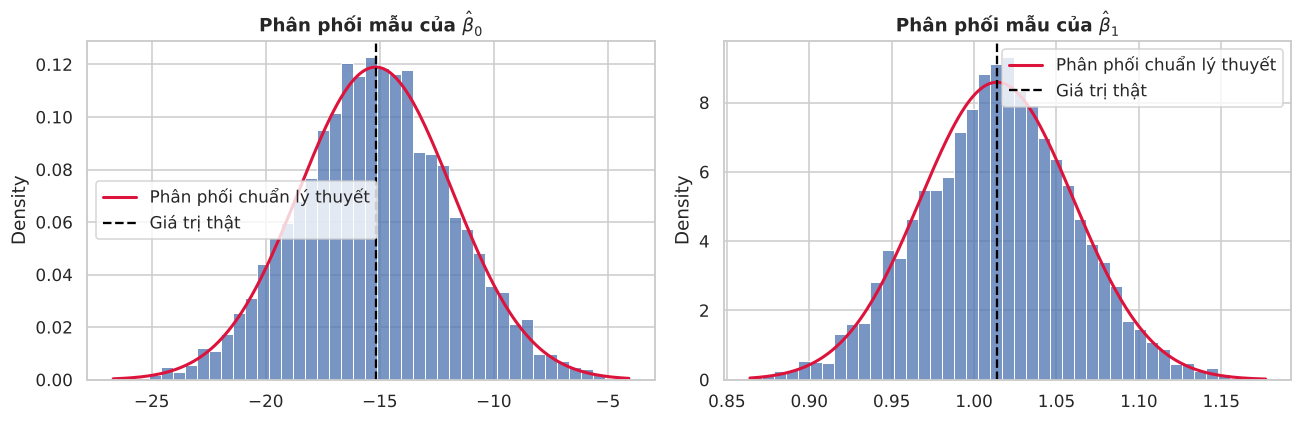

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sim, true, var, name in [(axes[0], b0_sim, b0, var_b0_th, r"$\hat\beta_0$"),
                                 (axes[1], b1_sim, b1, var_b1_th, r"$\hat\beta_1$")]:
    sns.histplot(sim, kde=False, stat="density", ax=ax, color="#4C72B0")
    g = np.linspace(sim.min(), sim.max(), 300)
    ax.plot(g, stats.norm.pdf(g, true, np.sqrt(var)), color="crimson", lw=2, label="Phân phối chuẩn lý thuyết")
    ax.axvline(true, color="black", ls="--", label="Giá trị thật"); ax.set_title(f"Phân phối mẫu của {name}"); ax.legend()
plt.show()

> Histogram mô phỏng khớp với phân phối chuẩn lý thuyết, tâm tại giá trị thật: các ước lượng **không chệch** và có phương sai đúng như công thức.

## 6. Kiểm định giả thuyết trong hồi quy tuyến tính *(mục 4.1.4)*

### 6.1. Kiểm định hệ số góc $\beta_1$
$H_0:\beta_1=\beta_{1,0}$ với $H_1:\beta_1\neq\beta_{1,0}$. Thống kê kiểm định
$$T=\frac{\hat\beta_1-\beta_{1,0}}{se(\hat\beta_1)}\ \sim\ t_{n-2}\ \text{ khi } H_0 \text{ đúng};$$
bác bỏ $H_0$ nếu $|T|>t_{\alpha/2,\,n-2}$ (hay $p$-value $<\alpha$). Trường hợp quan trọng nhất là $\beta_{1,0}=0$: kiểm tra $x$ **có ảnh hưởng tuyến tính** đến $Y$ hay không.

### 6.2. Kiểm định hệ số chặn $\beta_0$
Tương tự với $T=\dfrac{\hat\beta_0-\beta_{0,0}}{se(\hat\beta_0)}\sim t_{n-2}$.

In [16]:
df_res = n - 2
t_crit = stats.t.ppf(1 - ALPHA / 2, df_res)

def t_test(est, se, h0=0.0, alpha=ALPHA):
    t = (est - h0) / se
    p = 2 * stats.t.sf(abs(t), df_res)
    return t, p, ("Bác bỏ H0" if p < alpha else "Không bác bỏ H0")

tests = [
    ("β1 = 0 (x không ảnh hưởng tuyến tính)", b1, se_b1, 0.0),
    ("β0 = 0",                                 b0, se_b0, 0.0),
    ("β1 = 1 (thử một giá trị khác 0)",        b1, se_b1, 1.0),
]
out = []
for name, est, se, h0 in tests:
    t, p, dec = t_test(est, se, h0)
    out.append({"Giả thuyết H0": name, "Ước lượng": est, "se": se, "T": t, "p-value": p, f"Kết luận (α={ALPHA})": dec})
print(f"Giá trị tới hạn t(α/2, n-2) = {t_crit:.4f}")
pd.DataFrame(out)

Giá trị tới hạn t(α/2, n-2) = 1.9602


,Giả thuyết H0,Ước lượng,se,T,p-value,Kết luận (α=0.05)
0,β1 = 0 (x không ảnh hưởng tuyến tính),1.0138,0.0045,227.0575,0.0000,Bác bỏ H0
1,β0 = 0,-15.1818,0.3196,-47.5017,0.0000,Bác bỏ H0
2,β1 = 1 (thử một giá trị khác 0),1.0138,0.0045,3.0988,0.0019,Bác bỏ H0


> **Nhận xét.** Với $H_0:\beta_1=0$, $|T|$ rất lớn và $p$-value $\approx 0$ ⇒ bác bỏ $H_0$: *điểm số trước đó có ảnh hưởng tuyến tính có ý nghĩa thống kê đến chỉ số kết quả học tập.* Lưu ý cỡ mẫu $n=10\,000$ lớn nên kiểm định rất "nhạy"; ý nghĩa thực tiễn cần xem thêm ở độ lớn hệ số và $R^2$.

### 6.3. Kiểm định ý nghĩa của hồi quy và phân tích phương sai (ANOVA)
Phân rã tổng bình phương:
$$SS_T=\sum(y_i-\bar y)^2=\underbrace{\sum(\hat y_i-\bar y)^2}_{SS_R}+\underbrace{\sum(y_i-\hat y_i)^2}_{SS_E},\qquad SS_R=\hat\beta_1S_{xy}.$$
Kiểm định $H_0:\beta_1=0$ bằng thống kê
$$F=\frac{MS_R}{MS_E}=\frac{SS_R/1}{SS_E/(n-2)}\ \sim\ F_{1,\,n-2},$$
và trong hồi quy đơn $F=T^2$.

In [17]:
SST = Syy
SSR = b1 * Sxy
MSR = SSR / 1
MSE = SSE / (n - 2)
F = MSR / MSE
p_F = stats.f.sf(F, 1, n - 2)

anova = pd.DataFrame({
    "Nguồn biến thiên": ["Hồi quy (SSR)", "Sai số (SSE)", "Tổng (SST)"],
    "Tổng bình phương": [SSR, SSE, SST],
    "Bậc tự do": [1, n - 2, n - 1],
    "Trung bình bình phương": [MSR, MSE, np.nan],
    "F": [F, np.nan, np.nan],
    "p-value": [p_F, np.nan, np.nan],
})
display(anova.style.format({"Tổng bình phương": "{:,.2f}", "Trung bình bình phương": "{:,.4f}",
                            "F": "{:,.2f}", "p-value": "{:.3e}"}, na_rep=""))
print(f"Kiểm tra SST = SSR + SSE : {SST:,.4f} = {SSR + SSE:,.4f}")
print(f"Kiểm tra F = T² : F = {F:,.4f}  |  T² = {((b1 - 0) / se_b1) ** 2:,.4f}")
print(f"statsmodels F = {ols.fvalue:,.4f}, p = {ols.f_pvalue:.3e}")

,Nguồn biến thiên,Tổng bình phương,Bậc tự do,Trung bình bình phương,F,p-value
0,Hồi quy (SSR),"3,091,353.43",1,"3,091,353.4258","51,555.11",0.000e+00
1,Sai số (SSE),"599,501.22",9998,59.9621,,
2,Tổng (SST),"3,690,854.65",9999,,,


Kiểm tra SST = SSR + SSE : 3,690,854.6496 = 3,690,854.6496
Kiểm tra F = T² : F = 51,555.1100  |  T² = 51,555.1100
statsmodels F = 51,555.1100, p = 0.000e+00


### 6.4. Bảng tóm tắt từ `statsmodels` (đối chiếu)

In [18]:
print(ols.summary(xname=["const (β0)", "Previous Scores (β1)"], yname="Performance Index"))

                            OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.838
Method:                 Least Squares   F-statistic:                 5.156e+04
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        06:46:15   Log-Likelihood:                -34657.
No. Observations:               10000   AIC:                         6.932e+04
Df Residuals:                    9998   BIC:                         6.933e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const (β0)             -15.1818 

## 7. Khoảng tin cậy trong hồi quy tuyến tính *(mục 4.1.5)*

### 7.1. Khoảng tin cậy cho $\beta_0,\beta_1$
Khoảng tin cậy $100(1-\alpha)\%$:
$$\hat\beta_1\pm t_{\alpha/2,\,n-2}\,se(\hat\beta_1),\qquad \hat\beta_0\pm t_{\alpha/2,\,n-2}\,se(\hat\beta_0).$$

In [19]:
ci_b1 = (b1 - t_crit * se_b1, b1 + t_crit * se_b1)
ci_b0 = (b0 - t_crit * se_b0, b0 + t_crit * se_b0)
sm_ci = ols.conf_int(ALPHA)

pd.DataFrame({
    "Ước lượng": [b0, b1],
    "Cận dưới (tay)": [ci_b0[0], ci_b1[0]], "Cận trên (tay)": [ci_b0[1], ci_b1[1]],
    "Cận dưới (statsmodels)": sm_ci[:, 0], "Cận trên (statsmodels)": sm_ci[:, 1],
}, index=["β0", "β1"])

,Ước lượng,Cận dưới (tay),Cận trên (tay),Cận dưới (statsmodels),Cận trên (statsmodels)
β0,-15.1818,-15.8083,-14.5553,-15.8083,-14.5553
β1,1.0138,1.0051,1.0226,1.0051,1.0226


> Khoảng tin cậy của $\beta_1$ **không chứa 0**, nhất quán với việc bác bỏ $H_0:\beta_1=0$ ở mục 6.

### 7.2. Khoảng tin cậy cho giá trị trung bình $\mu_{Y|x_0}$
$$\hat\mu_{Y|x_0}\pm t_{\alpha/2,\,n-2}\sqrt{\hat\sigma^2\Big[\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}\Big]}.$$

### 7.3. Khoảng dự đoán cho một quan sát mới $Y_0$ tại $x_0$
$$\hat y_0\pm t_{\alpha/2,\,n-2}\sqrt{\hat\sigma^2\Big[1+\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}\Big]}.$$
Khoảng dự đoán **rộng hơn** vì còn chứa độ biến thiên của sai số $\varepsilon_0$ của một cá thể mới.

In [20]:
def interval(x0, alpha=ALPHA):
    # Trả về ŷ0, khoảng tin cậy cho trung bình, khoảng dự đoán cho quan sát mới.
    x0 = np.atleast_1d(np.asarray(x0, dtype=float))
    tc = stats.t.ppf(1 - alpha / 2, n - 2)
    y0 = b0 + b1 * x0
    h = 1 / n + (x0 - x_bar) ** 2 / Sxx
    se_mean = np.sqrt(sigma2_hat * h)
    se_pred = np.sqrt(sigma2_hat * (1 + h))
    return pd.DataFrame({"x0": x0, "ŷ0": y0,
                         "CI_dưới": y0 - tc * se_mean, "CI_trên": y0 + tc * se_mean,
                         "PI_dưới": y0 - tc * se_pred, "PI_trên": y0 + tc * se_pred})

x0_list = [40, 55, 70, 85, 99]
tab = interval(x0_list)
display(tab)

# đối chiếu với statsmodels
sm_pred = ols.get_prediction(sm.add_constant(np.array(x0_list, dtype=float))).summary_frame(alpha=ALPHA)
print("Sai khác lớn nhất so với statsmodels:",
      float(np.abs(tab[["CI_dưới", "CI_trên"]].to_numpy() - sm_pred[["mean_ci_lower", "mean_ci_upper"]].to_numpy()).max()),
      "|", float(np.abs(tab[["PI_dưới", "PI_trên"]].to_numpy() - sm_pred[["obs_ci_lower", "obs_ci_upper"]].to_numpy()).max()))

,x0,ŷ0,CI_dưới,CI_trên,PI_dưới,PI_trên
0,40.0000,25.3717,25.0726,25.6708,10.1899,40.5535
1,55.0000,40.5792,40.3817,40.7768,25.3991,55.7594
2,70.0000,55.7868,55.6349,55.9386,40.6072,70.9664
3,85.0000,70.9943,70.7904,71.1982,55.8141,86.1745
4,99.0000,85.1880,84.8881,85.4880,70.0062,100.3699


Sai khác lớn nhất so với statsmodels: 2.842170943040401e-14 | 2.842170943040401e-14


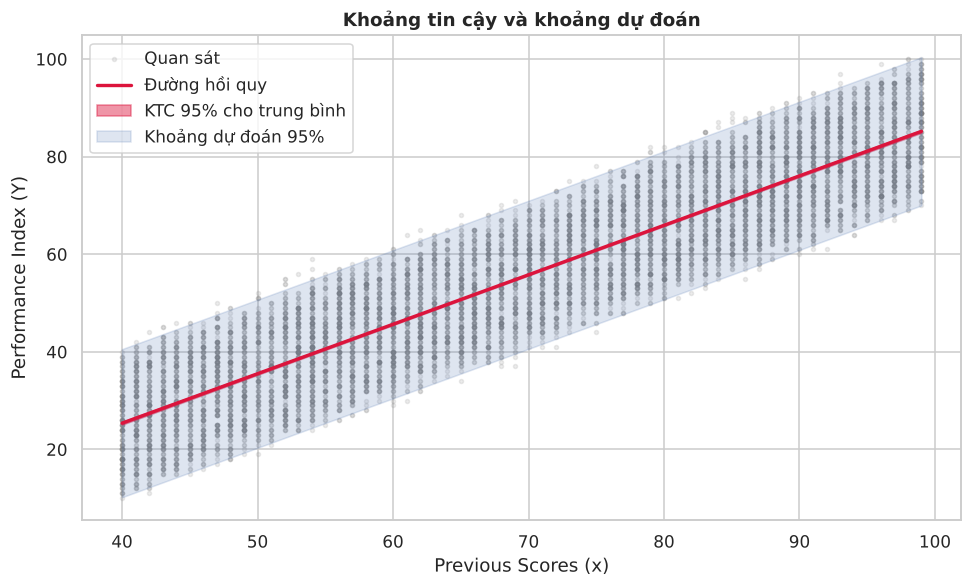

Tỉ lệ quan sát nằm trong khoảng dự đoán 95%: 98.8%  (kỳ vọng ≈ 95%)


In [21]:
grid = np.linspace(x.min(), x.max(), 200)
iv = interval(grid)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(x, y, s=7, alpha=0.15, color="gray", label="Quan sát")
ax.plot(iv["x0"], iv["ŷ0"], color="crimson", lw=2.2, label="Đường hồi quy")
ax.fill_between(iv["x0"], iv["CI_dưới"], iv["CI_trên"], color="crimson", alpha=0.45, label="KTC 95% cho trung bình")
ax.fill_between(iv["x0"], iv["PI_dưới"], iv["PI_trên"], color="#4C72B0", alpha=0.18, label="Khoảng dự đoán 95%")
ax.set_xlabel("Previous Scores (x)"); ax.set_ylabel("Performance Index (Y)")
ax.set_title("Khoảng tin cậy và khoảng dự đoán"); ax.legend()
plt.show()

iv_all = interval(x)
cover = np.mean((y >= iv_all["PI_dưới"].to_numpy()) & (y <= iv_all["PI_trên"].to_numpy()))
print(f"Tỉ lệ quan sát nằm trong khoảng dự đoán 95%: {cover:.1%}  (kỳ vọng ≈ 95%)")

> Dải khoảng tin cậy (cho **giá trị trung bình**) rất hẹp vì $n$ lớn, trong khi dải dự đoán (cho **một sinh viên cụ thể**) rộng hơn nhiều. Cả hai hẹp nhất tại $\bar x$ và loe ra ở hai đầu.
>
> Khoảng dự đoán danh nghĩa 95% thực tế phủ khoảng **98,8%** quan sát, tức **bảo thủ (rộng thừa)**. Lý do là phần dư nhẹ đuôi hơn phân phối chuẩn (xem mục 8.1): công thức khoảng dự đoán giả định $\varepsilon$ chuẩn nên cho cận rộng hơn mức cần thiết. Khoảng tin cậy của hệ số và của giá trị trung bình không bị ảnh hưởng đáng kể nhờ $n$ lớn.

## 8. Tính đủ của mô hình hồi quy *(mục 4.1.6)*

### 8.1. Phân tích phần dư
Phần dư $e_i=y_i-\hat y_i$. Ta kiểm tra các giả thiết $\varepsilon\sim N(0,\sigma^2)$ bằng:
- **Biểu đồ tần suất / biểu đồ xác suất chuẩn (Q–Q)** của phần dư → tính chuẩn;
- **Phần dư chuẩn hóa** $d_i=e_i/\hat\sigma$: nếu sai số chuẩn thì khoảng 95% $d_i\in(-2,2)$; giá trị ngoài khoảng gợi ý **ngoại lai**;
- **Biểu đồ phần dư theo $\hat y_i$ và theo $x_i$** → phương sai không đổi, tính tuyến tính. Mẫu lý tưởng là đám mây điểm ngẫu nhiên quanh 0; dạng *phễu*, *cung đôi* hay *cong* báo hiệu mô hình chưa phù hợp.

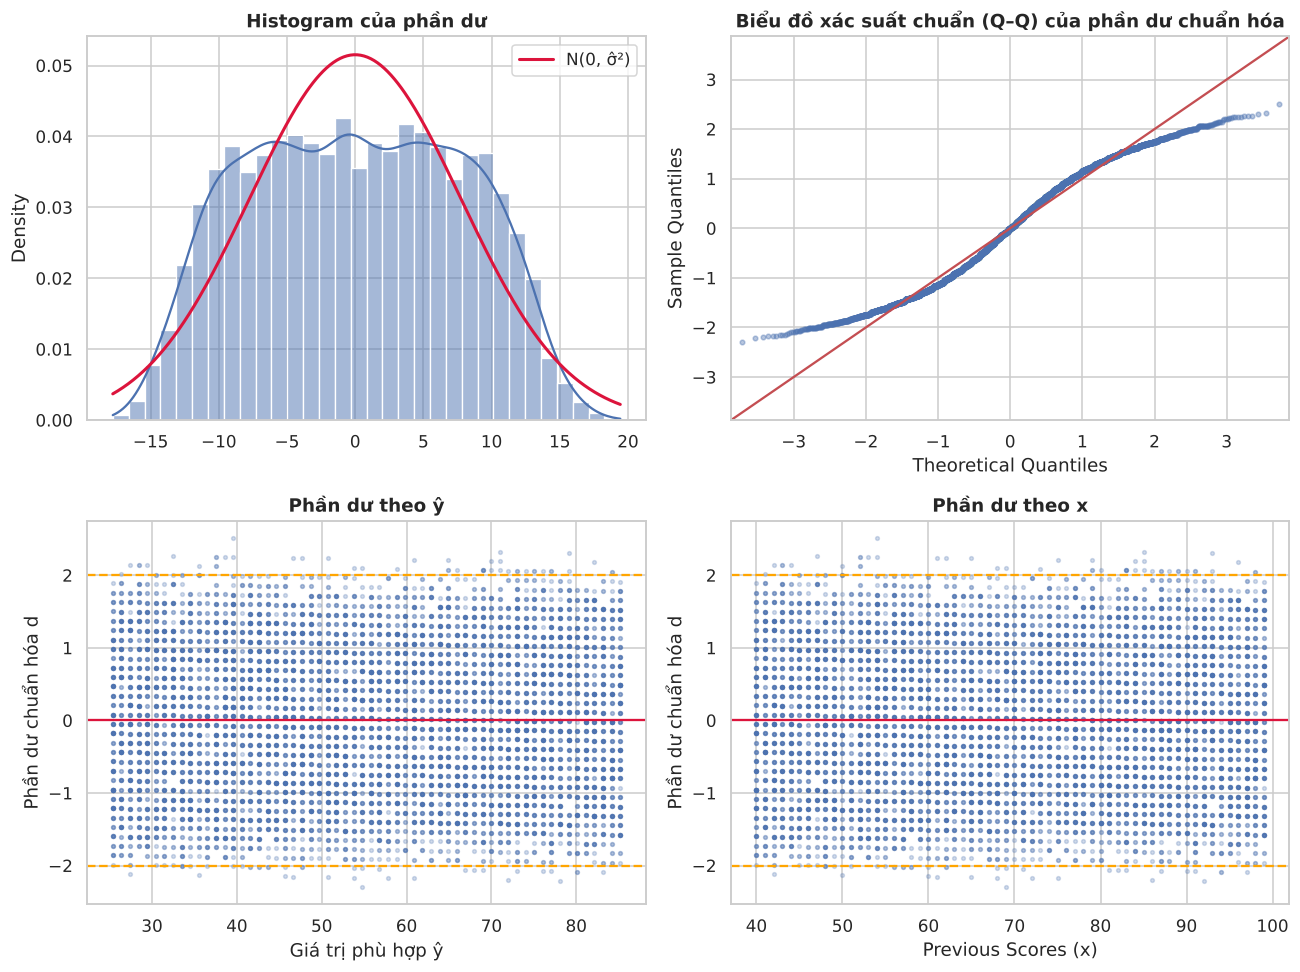

In [22]:
d = e / sigma_hat   # phần dư chuẩn hóa

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(e, kde=True, stat="density", ax=axes[0, 0], color="#4C72B0")
g = np.linspace(e.min(), e.max(), 300)
axes[0, 0].plot(g, stats.norm.pdf(g, 0, sigma_hat), color="crimson", lw=2, label="N(0, σ̂²)")
axes[0, 0].set_title("Histogram của phần dư"); axes[0, 0].legend()

sm.qqplot(d, line="45", ax=axes[0, 1], markersize=3, alpha=0.4)
axes[0, 1].set_title("Biểu đồ xác suất chuẩn (Q–Q) của phần dư chuẩn hóa")

axes[1, 0].scatter(y_hat, d, s=6, alpha=0.25)
axes[1, 0].axhline(0, color="crimson"); axes[1, 0].axhline(2, color="orange", ls="--"); axes[1, 0].axhline(-2, color="orange", ls="--")
axes[1, 0].set_xlabel("Giá trị phù hợp ŷ"); axes[1, 0].set_ylabel("Phần dư chuẩn hóa d"); axes[1, 0].set_title("Phần dư theo ŷ")

axes[1, 1].scatter(x, d, s=6, alpha=0.25)
axes[1, 1].axhline(0, color="crimson"); axes[1, 1].axhline(2, color="orange", ls="--"); axes[1, 1].axhline(-2, color="orange", ls="--")
axes[1, 1].set_xlabel("Previous Scores (x)"); axes[1, 1].set_ylabel("Phần dư chuẩn hóa d"); axes[1, 1].set_title("Phần dư theo x")
plt.show()

In [23]:
# Định lượng hóa các nhận xét từ đồ thị
out2 = (np.abs(d) > 2).mean(); out3 = (np.abs(d) > 3).sum()
print(f"Tỉ lệ |d| > 2 : {out2:.2%}  (nếu chuẩn ≈ 4.55%)")
print(f"Số quan sát |d| > 3 : {out3}  (nếu chuẩn ≈ {n * 0.0027:.0f})")
print(f"Độ lệch (skewness) = {stats.skew(e):.4f} | Độ nhọn dư (excess kurtosis) = {stats.kurtosis(e):.4f}")

sh_stat, sh_p = stats.shapiro(np.random.default_rng(RANDOM_STATE).choice(e, 5000, replace=False))
jb_stat, jb_p = stats.jarque_bera(e)
bp_stat, bp_p, _, _ = het_breuschpagan(e, X_sm)
print(f"\nShapiro–Wilk (mẫu 5000): W = {sh_stat:.4f}, p = {sh_p:.4f}")
print(f"Jarque–Bera            : JB = {jb_stat:.3f}, p = {jb_p:.4f}")
print(f"Breusch–Pagan (phương sai đồng nhất): LM = {bp_stat:.3f}, p = {bp_p:.4f}")

Tỉ lệ |d| > 2 : 0.92%  (nếu chuẩn ≈ 4.55%)
Số quan sát |d| > 3 : 0  (nếu chuẩn ≈ 27)
Độ lệch (skewness) = 0.0113 | Độ nhọn dư (excess kurtosis) = -1.0175

Shapiro–Wilk (mẫu 5000): W = 0.9781, p = 0.0000
Jarque–Bera            : JB = 431.609, p = 0.0000
Breusch–Pagan (phương sai đồng nhất): LM = 1.845, p = 0.1744


> **Nhận xét (đọc cùng đồ thị và các kiểm định phía trên).**
> - **Tuyến tính – đạt.** Phần dư theo $\hat y$ và theo $x$ là đám mây ngẫu nhiên quanh 0, **không có dạng cong** ⇒ hàm hồi quy tuyến tính là phù hợp (mẫu (a) trong slide).
> - **Phương sai không đổi – đạt.** Dải phần dư có bề rộng đều dọc theo $\hat y$ và $x$, **không có dạng phễu**; Breusch–Pagan có $p\approx0{,}17>0{,}05$ nên không bác bỏ phương sai đồng nhất.
> - **Tính chuẩn – chỉ đạt ở mức xấp xỉ, có sai lệch rõ.** Phần dư đối xứng (độ lệch $\approx0$) nhưng có phân phối **"dẹt", nhẹ đuôi** (độ nhọn dư $\approx-1$): histogram thấp và rộng hơn đường chuẩn, Q–Q có dạng chữ S, chỉ khoảng 1% (thay vì 4,55%) phần dư chuẩn hóa vượt ±2 và không có quan sát nào vượt ±3. Shapiro–Wilk và Jarque–Bera bác bỏ tính chuẩn. Nguyên nhân hợp lý: phần biến thiên còn lại của $Y$ đến từ các biến khác (số giờ học, đề luyện, giấc ngủ…) vốn nhận giá trị trong miền hữu hạn nên sai số bị chặn hai đầu.
> - **Ngoại lai – không có.** Không có quan sát nào bất thường cần xem xét loại bỏ.
>
> **Hệ quả.** Vì $n=10\,000$ rất lớn, theo định lý giới hạn trung tâm các ước lượng $\hat\beta_0,\hat\beta_1$ vẫn xấp xỉ chuẩn, nên các kiểm định $t$, $F$ và khoảng tin cậy cho **hệ số** vẫn đáng tin. Riêng **khoảng dự đoán** cho từng cá thể (mục 7.3) phụ thuộc trực tiếp vào tính chuẩn của $\varepsilon$ nên sẽ hơi **rộng thừa** (xem mục 7.3 và 10.2).

### 8.2. Hệ số xác định $R^2$
$$R^2=\frac{SS_R}{SS_T}=1-\frac{SS_E}{SS_T}\in[0,1],$$
cho biết tỉ lệ biến thiên của $Y$ được giải thích bởi mô hình. Trong hồi quy đơn $R^2=r^2$ với $r$ là hệ số tương quan mẫu.

In [24]:
R2 = SSR / SST
r = Sxy / np.sqrt(Sxx * Syy)
R2_adj = 1 - (1 - R2) * (n - 1) / (n - 2)
print(f"R²              = {R2:.6f}  ({R2:.2%} biến thiên của Y được giải thích bởi x)")
print(f"r (tương quan)  = {r:.6f}   →  r² = {r**2:.6f}  (= R²)")
print(f"R² hiệu chỉnh   = {R2_adj:.6f}")
print(f"statsmodels R²  = {ols.rsquared:.6f}")
print(f"σ̂ (độ lệch chuẩn phần dư) = {sigma_hat:.4f} đơn vị Performance Index")

R²              = 0.837571  (83.76% biến thiên của Y được giải thích bởi x)
r (tương quan)  = 0.915189   →  r² = 0.837571  (= R²)
R² hiệu chỉnh   = 0.837555
statsmodels R²  = 0.837571
σ̂ (độ lệch chuẩn phần dư) = 7.7435 đơn vị Performance Index


### 8.3. Mối liên hệ giữa $\hat\beta_1$ và hệ số tương quan
$$\hat\beta_1=r\,\frac{s_y}{s_x}.$$

In [25]:
print(f"r·(s_y/s_x) = {r * y.std(ddof=1) / x.std(ddof=1):.6f}   |   β̂1 = {b1:.6f}")

r·(s_y/s_x) = 1.013837   |   β̂1 = 1.013837


### 8.4. Ý nghĩa của hệ số chặn
Hệ số chặn $\hat\beta_0$ là giá trị trung bình ước lượng của $Y$ khi $x=0$. Chỉ diễn giải được nếu $x=0$ **nằm trong (hoặc gần) miền dữ liệu** và có ý nghĩa thực tế. Ở đây `Previous Scores` chỉ nhận giá trị từ khoảng 40 đến 99, nên $x=0$ là **ngoại suy**, và $\hat\beta_0$ chỉ là hằng số điều chỉnh vị trí đường thẳng, không nên diễn giải như "chỉ số kết quả của sinh viên có điểm trước đó bằng 0".

Để có hệ số chặn **có ý nghĩa**, ta có thể **tâm hóa** $x$: đặt $x^*=x-\bar x$. Khi đó hệ số chặn mới chính là $\bar y$ — chỉ số kết quả trung bình của sinh viên có điểm trước đó ở mức trung bình.

In [26]:
ols_c = sm.OLS(y, sm.add_constant(x - x_bar)).fit()
print(f"Mô hình gốc      : ŷ = {b0:.4f} + {b1:.4f}·x            (x = 0 nằm ngoài miền dữ liệu [{x.min():.0f}, {x.max():.0f}])")
print(f"Mô hình tâm hóa  : ŷ = {ols_c.params[0]:.4f} + {ols_c.params[1]:.4f}·(x - {x_bar:.2f})")
print(f"→ hệ số chặn mới = {ols_c.params[0]:.4f} = ȳ = {y_bar:.4f}; hệ số góc không đổi.")

Mô hình gốc      : ŷ = -15.1818 + 1.0138·x            (x = 0 nằm ngoài miền dữ liệu [40, 99])
Mô hình tâm hóa  : ŷ = 55.2248 + 1.0138·(x - 69.45)
→ hệ số chặn mới = 55.2248 = ȳ = 55.2248; hệ số góc không đổi.


## 9. Hồi quy trên các phép biến đổi *(mục 4.1.7)*

### 9.1. Lý thuyết
Khi hàm hồi quy thật sự phi tuyến hoặc phương sai không đồng nhất, đôi khi có thể đưa về dạng đường thẳng bằng phép biến đổi (mô hình *tuyến tính nội tại*), ví dụ:

| Mô hình gốc | Phép biến đổi | Dạng tuyến tính |
|---|---|---|
| $Y=\beta_0e^{\beta_1x}\varepsilon$ | $\ln Y$ | $\ln Y=\ln\beta_0+\beta_1x+\ln\varepsilon$ |
| $Y=\beta_0+\beta_1\dfrac1x+\varepsilon$ | $z=1/x$ | $Y=\beta_0+\beta_1z+\varepsilon$ |
| $Y=\beta_0+\beta_1\ln x+\varepsilon$ | $z=\ln x$ | $Y=\beta_0+\beta_1z+\varepsilon$ |
| Phương sai tăng theo $Y$ | $\sqrt Y$ hoặc $\ln Y$ | ổn định phương sai |

Phép biến đổi cần số hạng sai số *đã biến đổi* vẫn $N_{iid}(0,\sigma^2)$.

### 9.2. Thử các phép biến đổi trên dữ liệu
Do phần dư của mô hình tuyến tính ở mục 8 đã tốt, ta **không kỳ vọng** phép biến đổi cải thiện mô hình. Ta vẫn thử để kiểm chứng. Để so sánh công bằng, mọi mô hình được đánh giá bằng $R^2$ và RMSE **trên thang đo gốc của $Y$** (dự đoán từ mô hình $\ln Y$, $\sqrt Y$ được đổi ngược về $Y$).

In [27]:
def fit_transform(name, x_t, y_t, back):
    # Hồi quy y_t theo x_t rồi đổi ngược về thang đo gốc để so sánh.
    m = sm.OLS(y_t, sm.add_constant(x_t)).fit()
    yh = back(m.fittedvalues)
    return m, yh

specs = {
    "Y ~ x  (gốc)":      (x,            y,            lambda v: v),
    "ln Y ~ x":          (x,            np.log(y),    np.exp),
    "√Y ~ x":            (x,            np.sqrt(y),   lambda v: v ** 2),
    "Y ~ 1/x":           (1 / x,        y,            lambda v: v),
    "Y ~ ln x":          (np.log(x),    y,            lambda v: v),
}
models, preds, rows = {}, {}, []
for name, (xt, yt, back) in specs.items():
    m, yh = fit_transform(name, xt, yt, back)
    models[name], preds[name] = m, yh
    resid_t = m.resid
    rows.append({"Mô hình": name,
                 "R² (thang biến đổi)": m.rsquared,
                 "R² (thang gốc của Y)": r2_score(y, yh),
                 "RMSE (thang gốc)": np.sqrt(mean_squared_error(y, yh)),
                 "Độ lệch phần dư": stats.skew(resid_t),
                 "p Breusch–Pagan": het_breuschpagan(resid_t, sm.add_constant(xt))[1]})
cmp_tab = pd.DataFrame(rows).set_index("Mô hình")
cmp_tab

,R² (thang biến đổi),R² (thang gốc của Y),RMSE (thang gốc),Độ lệch phần dư,p Breusch–Pagan
Mô hình,,,,,
Y ~ x (gốc),0.8376,0.8376,7.7427,0.0113,0.1744
ln Y ~ x,0.7812,0.8102,8.3708,-0.7745,0.0000
√Y ~ x,0.8226,0.8322,7.8702,-0.2280,0.0000
Y ~ 1/x,0.7917,0.7917,8.7682,0.0818,0.0001
Y ~ ln x,0.8261,0.8261,8.0106,0.0317,0.0226


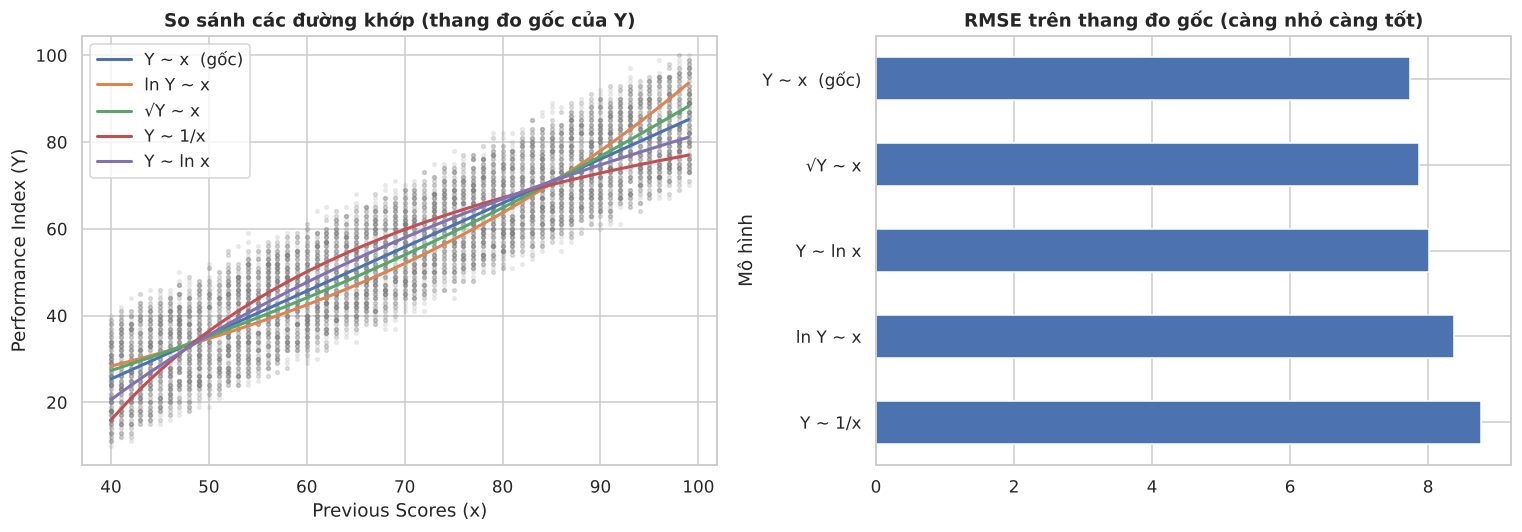

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(x, y, s=6, alpha=0.12, color="gray")
order = np.argsort(x)
for name, yh in preds.items():
    axes[0].plot(x[order], yh[order], lw=2, label=name)
axes[0].set_title("So sánh các đường khớp (thang đo gốc của Y)")
axes[0].set_xlabel("Previous Scores (x)"); axes[0].set_ylabel("Performance Index (Y)"); axes[0].legend()

cmp_tab["RMSE (thang gốc)"].sort_values().plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("RMSE trên thang đo gốc (càng nhỏ càng tốt)"); axes[1].invert_yaxis()
plt.show()

In [29]:
best = cmp_tab["RMSE (thang gốc)"].idxmin()
print("Mô hình có RMSE nhỏ nhất:", best)
print(f"Chênh lệch RMSE so với mô hình gốc: {cmp_tab.loc[best, 'RMSE (thang gốc)'] - cmp_tab.loc['Y ~ x  (gốc)', 'RMSE (thang gốc)']:+.4f}")

Mô hình có RMSE nhỏ nhất: Y ~ x  (gốc)
Chênh lệch RMSE so với mô hình gốc: +0.0000


> **Kết luận mục 9.** Mô hình tuyến tính gốc có RMSE nhỏ nhất và $R^2$ cao nhất trên thang đo của $Y$. Các phép biến đổi không những không cải thiện mà còn **làm xấu giả thiết**: $\ln Y$ và $\sqrt Y$ làm phần dư bị lệch (độ lệch $\approx-0{,}77$ và $-0{,}23$) và khiến Breusch–Pagan bác bỏ phương sai đồng nhất ($p\approx0$); $1/x$ và $\ln x$ cho $R^2$ thấp hơn. Đây là kết quả hợp lý vì biểu đồ phân tán và phần dư (mục 8) đã cho thấy quan hệ tuyến tính, phương sai đồng nhất, không cần "chữa". Vì vậy **ta giữ mô hình $Y=\beta_0+\beta_1x+\varepsilon$** làm mô hình cuối cùng — đồng thời dễ diễn giải hơn (mỗi điểm tăng của `Previous Scores` ứng với $\hat\beta_1$ đơn vị tăng của `Performance Index`).

## 10. Dự đoán và đánh giá mô hình

### 10.1. Đánh giá trên tập kiểm tra (hold-out)
Để kiểm tra khả năng **dự đoán** trên dữ liệu chưa thấy, chia ngẫu nhiên 80% huấn luyện – 20% kiểm tra, ước lượng lại $\hat\beta_0,\hat\beta_1$ **chỉ trên tập huấn luyện** rồi đo sai số trên tập kiểm tra.

In [30]:
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=RANDOM_STATE)

m_tr = sm.OLS(y_tr, sm.add_constant(x_tr)).fit()
y_te_hat = m_tr.predict(sm.add_constant(x_te))

metrics = pd.DataFrame({
    "Tập": ["Huấn luyện", "Kiểm tra"],
    "n": [len(x_tr), len(x_te)],
    "R²": [r2_score(y_tr, m_tr.fittedvalues), r2_score(y_te, y_te_hat)],
    "MAE": [mean_absolute_error(y_tr, m_tr.fittedvalues), mean_absolute_error(y_te, y_te_hat)],
    "RMSE": [np.sqrt(mean_squared_error(y_tr, m_tr.fittedvalues)), np.sqrt(mean_squared_error(y_te, y_te_hat))],
}).set_index("Tập")
print(f"Mô hình trên tập huấn luyện: ŷ = {m_tr.params[0]:.4f} + {m_tr.params[1]:.4f}·x")
metrics

Mô hình trên tập huấn luyện: ŷ = -15.1044 + 1.0127·x


,n,R²,MAE,RMSE
Tập,,,,
Huấn luyện,8000,0.8367,6.6229,7.7589
Kiểm tra,2000,0.8409,6.5575,7.6778


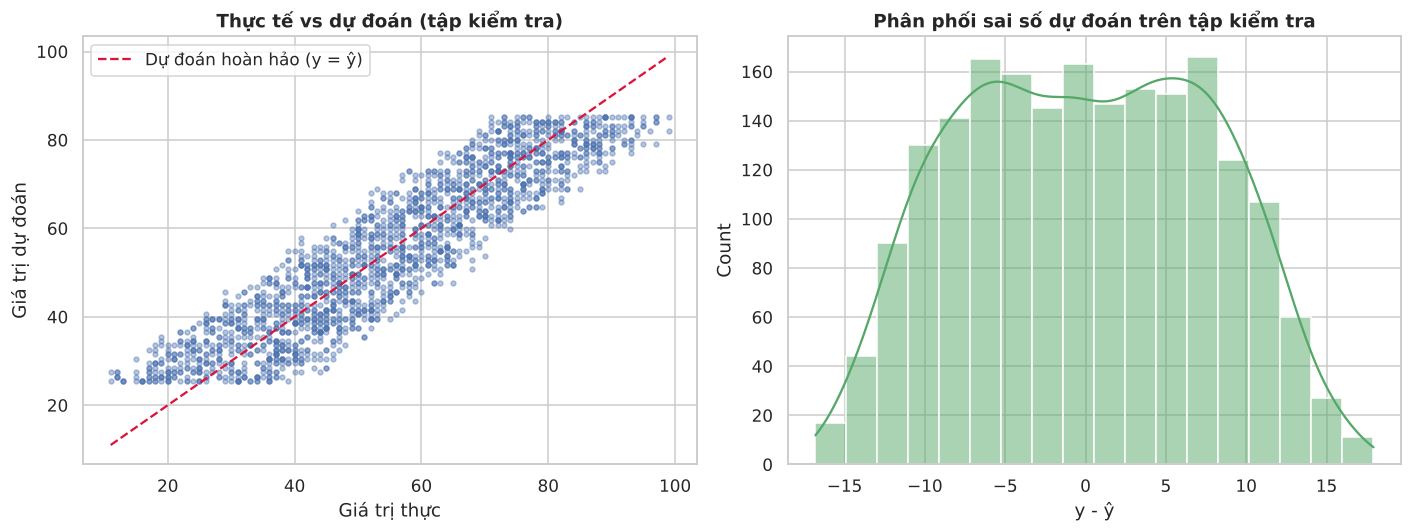

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_te, y_te_hat, s=10, alpha=0.4)
lim = [min(y_te.min(), y_te_hat.min()), max(y_te.max(), y_te_hat.max())]
axes[0].plot(lim, lim, color="crimson", ls="--", label="Dự đoán hoàn hảo (y = ŷ)")
axes[0].set_xlabel("Giá trị thực"); axes[0].set_ylabel("Giá trị dự đoán"); axes[0].set_title("Thực tế vs dự đoán (tập kiểm tra)"); axes[0].legend()

sns.histplot(y_te - y_te_hat, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("Phân phối sai số dự đoán trên tập kiểm tra"); axes[1].set_xlabel("y - ŷ")
plt.show()

> $R^2$ và RMSE trên tập kiểm tra gần như bằng trên tập huấn luyện ⇒ mô hình **không quá khớp**, tổng quát hóa tốt.

### 10.2. Dự đoán cho sinh viên mới
Với mô hình cuối cùng (ước lượng trên toàn bộ dữ liệu) ta dự đoán `Performance Index` tại điểm số trước đó $x_0$ cho trước, kèm khoảng tin cậy cho trung bình và khoảng dự đoán cho một sinh viên cụ thể.

In [32]:
def predict_performance(previous_score, alpha=ALPHA):
    # Dự đoán Performance Index từ Previous Scores, kèm KTC trung bình và khoảng dự đoán.
    score = np.atleast_1d(previous_score).astype(float)
    if (score < x.min()).any() or (score > x.max()).any():
        print(f"⚠ Cảnh báo: có điểm nằm ngoài miền dữ liệu [{x.min():.0f}, {x.max():.0f}] → đây là NGOẠI SUY, kết quả kém tin cậy.")
    res = interval(score, alpha).rename(columns={"x0": "Previous Scores", "ŷ0": "Dự đoán"})
    return res.round(2)

predict_performance([45, 60, 75, 90, 99])

,Previous Scores,Dự đoán,CI_dưới,CI_trên,PI_dưới,PI_trên
0,45.0000,30.4400,30.1800,30.7000,15.2600,45.6200
1,60.0000,45.6500,45.4800,45.8200,30.4700,60.8300
2,75.0000,60.8600,60.7000,61.0200,45.6800,76.0400
3,90.0000,76.0600,75.8300,76.3000,60.8800,91.2400
4,99.0000,85.1900,84.8900,85.4900,70.0100,100.3700


In [33]:
# Ví dụ: một sinh viên có điểm trước đó 82
r82 = predict_performance(82).iloc[0]
print(f"Sinh viên có Previous Scores = 82:")
print(f"  • Chỉ số kết quả dự đoán           : {r82['Dự đoán']:.2f}")
print(f"  • KTC 95% cho giá trị TRUNG BÌNH   : [{r82['CI_dưới']:.2f}; {r82['CI_trên']:.2f}]")
print(f"  • Khoảng dự đoán 95% cho 1 sinh viên: [{r82['PI_dưới']:.2f}; {r82['PI_trên']:.2f}]")

Sinh viên có Previous Scores = 82:
  • Chỉ số kết quả dự đoán           : 67.95
  • KTC 95% cho giá trị TRUNG BÌNH   : [67.77; 68.14]
  • Khoảng dự đoán 95% cho 1 sinh viên: [52.77; 83.13]


> **Lưu ý khi dự đoán.** (i) Chỉ nên dự đoán trong miền giá trị $x$ của dữ liệu (nội suy). (ii) Khoảng dự đoán phản ánh độ bất định cho từng cá nhân, rộng hơn nhiều so với khoảng tin cậy của trung bình, và do phần dư nhẹ đuôi nên nó hơi rộng thừa (phủ ≈ 98,8% thay vì 95%). (iii) Chỉ số kết quả bị chặn ở 100 nên với $x$ rất cao, giá trị dự đoán cần được hiểu thận trọng.

## 11. Tổng kết và kết luận

In [34]:
summary = pd.DataFrame({
    "Chỉ tiêu": ["Cỡ mẫu n", "Hệ số chặn β̂0", "Hệ số góc β̂1", "KTC 95% cho β1", "σ̂ (độ lệch chuẩn sai số)",
                 "t (β1 = 0)", "F (ANOVA)", "p-value (F)", "R²", "RMSE kiểm tra (hold-out)"],
    "Giá trị": [f"{n:,}", f"{b0:.4f}", f"{b1:.4f}", f"[{ci_b1[0]:.4f}; {ci_b1[1]:.4f}]", f"{sigma_hat:.4f}",
                f"{b1 / se_b1:,.2f}", f"{F:,.2f}", f"{p_F:.3e}", f"{R2:.4f}", f"{metrics.loc['Kiểm tra', 'RMSE']:.4f}"],
}).set_index("Chỉ tiêu")
summary

,Giá trị
Chỉ tiêu,
Cỡ mẫu n,"10,000"
Hệ số chặn β̂0,-15.1818
Hệ số góc β̂1,1.0138
KTC 95% cho β1,[1.0051; 1.0226]
σ̂ (độ lệch chuẩn sai số),7.7435
t (β1 = 0),227.06
F (ANOVA),"51,555.11"
p-value (F),0.000e+00
R²,0.8376


### Kết luận

1. **Mô hình:** $\widehat{\text{Performance Index}}=\hat\beta_0+\hat\beta_1\cdot\text{Previous Scores}$ với các giá trị cụ thể ở bảng tổng kết trên.
2. **Ý nghĩa thống kê:** kiểm định $t$ và $F$ đều bác bỏ $H_0:\beta_1=0$ với $p\approx0$; khoảng tin cậy 95% cho $\beta_1$ rất hẹp và không chứa 0. `Previous Scores` có ảnh hưởng tuyến tính **thuận chiều** và có ý nghĩa đến `Performance Index`.
3. **Độ phù hợp:** $R^2\approx0{,}84$ — điểm số trước đó giải thích phần lớn biến thiên của chỉ số kết quả; phần còn lại do các yếu tố khác (số giờ học, đề luyện, giấc ngủ, …).
4. **Giả thiết mô hình:** phần dư không có dạng cong hay phễu, phương sai đồng nhất (Breusch–Pagan $p\approx0{,}17$) ⇒ mô hình tuyến tính là **đủ** về dạng hàm (4.1.6). Tính chuẩn của sai số chỉ thỏa mãn xấp xỉ (phần dư nhẹ đuôi); nhờ $n$ lớn nên các suy diễn về hệ số vẫn đáng tin, còn khoảng dự đoán hơi rộng thừa. Các phép biến đổi (4.1.7) không cải thiện thêm, thậm chí làm xấu giả thiết.
5. **Dự đoán:** sai số trên tập kiểm tra gần bằng tập huấn luyện ⇒ mô hình tổng quát hóa tốt; có thể dùng để dự đoán kèm khoảng dự đoán.

**Hạn chế và hướng mở rộng**
- Hồi quy đơn chỉ dùng một biến, $R^2$ chưa tuyệt đối. Việc đưa thêm `Hours Studied`, `Sleep Hours`, `Sample Question Papers Practiced`, `Extracurricular Activities` thuộc phạm vi **hồi quy tuyến tính bội** (mục sau của Chương 4).
- Giả thiết chuẩn của sai số bị vi phạm nhẹ (phân phối dẹt); nếu cần khoảng dự đoán chính xác hơn có thể dùng khoảng dự đoán theo phân vị thực nghiệm của phần dư.
- Tương quan không đồng nghĩa với nhân quả: kết quả chỉ nói điểm trước đó *đi cùng* chỉ số kết quả cao hơn.
- Dữ liệu có vẻ mang tính mô phỏng/giáo dục; nên thận trọng khi suy rộng ra thực tế.